# ML-Based Predictive Framework for Early Detection and Mitigation of Cyber Threats in Telemedicine Systems
### Revised analysis (v3) addressing reviewer comments

**Dataset:** WUSTL-EHMS-2020 (Washington University in St. Louis, Enhanced Healthcare Monitoring System), 16,318 records x 45 columns.

**Changes from v2 (reviewer comments)**
1. **Flow-state flags (`Flgs`) removed from the main model.** Per the Argus `ra(1)` manual, `M` means *multiple MAC addresses seen*
   on the flow (the attacker's MAC) and `R` in the ICMP-event position means an *ICMP Redirect* was mapped to the flow
   (typical of a forwarding man-in-the-middle host). Both are traces of the attacker's machine, not of attack behaviour.
2. **Leakage tolerance recorded:** lambda = 0.5, used as a review trigger (Step 8).
3. **Time-ordered split:** earlier 75% of records for training, later 25% for testing, with the cut placed between attack bursts.
   Cross-validation uses contiguous, burst-safe time blocks instead of shuffled folds.
4. **Significance tests:** McNemar's test between XGBoost and each baseline on the test set (Step 11).
5. **SHAP values** computed with XGBoost's built-in TreeSHAP (`pred_contribs=True`), so no extra package is needed (Step 15).
6. Earlier fixes: 600-dpi and PDF figure export; confusion matrices use the same `score >= 0.5` rule as the tables;
   ST = 0 is not treated as a missing reading.

### How to reproduce
Put `wustl-ehms-2020.csv` next to this notebook and run **Kernel -> Restart & Run All**. Outputs go to `outputs_v3/`.

In [1]:
import os, json, time, hashlib, hmac, secrets, warnings, platform
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, confusion_matrix, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)
import xgboost
from xgboost import XGBClassifier
import joblib
warnings.filterwarnings("ignore")

SEED = 42
DATA_FILE = "wustl-ehms-2020.csv"
OUTPUT_DIR = "outputs_v3"
LAMBDA = 0.5          # leakage tolerance: attributes with Lambda >= 0.5 are flagged for provenance review (Step 8)
TEST_SHARE = 0.25     # later 25% of the capture is the test period
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs(OUTPUT_DIR, exist_ok=True)
RESULTS = {}          # every number reported in the paper is stored here and saved in Step 18

ENV = {"python": platform.python_version(), "os": platform.platform(), "processor": platform.processor(),
       "sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "cpu_count": os.cpu_count()}
RESULTS["environment"] = ENV
print(ENV)

{'python': '3.13.9', 'os': 'Windows-11-10.0.26200-SP0', 'processor': 'Intel64 Family 6 Model 166 Stepping 0, GenuineIntel', 'sklearn': '1.7.2', 'xgboost': '3.4.1', 'numpy': '2.3.5', 'pandas': '2.3.3', 'cpu_count': 12}


In [2]:
AUDIT_LOG = os.path.join(OUTPUT_DIR, "audit_log.jsonl")
if os.path.exists(AUDIT_LOG):
    os.remove(AUDIT_LOG)               # fresh log for each full run

def audit(event, **details):
    record = {"time_utc": dt.datetime.now(dt.timezone.utc).isoformat(), "actor": "research_pipeline", "event": event, **details}
    with open(AUDIT_LOG, "a") as f:
        f.write(json.dumps(record, default=str) + "\n")

def fingerprint(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()

def save_fig(filename):
    plt.tight_layout()
    base = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(base, dpi=600, bbox_inches="tight")
    plt.savefig(base.replace(".png", ".pdf"), bbox_inches="tight")
    plt.show()

def burst_safe_blocks(labels, k):
    """Split a time-ordered label array into k contiguous blocks whose boundaries never cut through an attack burst."""
    n = len(labels)
    bounds = [round(i * n / k) for i in range(k + 1)]
    for i in range(1, k):
        while labels[bounds[i]] == 1 or labels[bounds[i] - 1] == 1:
            bounds[i] += 1
    idx = np.arange(n)
    folds = [(np.r_[idx[:bounds[i]], idx[bounds[i + 1]:]], idx[bounds[i]:bounds[i + 1]]) for i in range(k)]
    return folds, bounds

## Step 3: Load the data

In [3]:
raw = pd.read_csv(DATA_FILE)
raw_hash = fingerprint(raw)
audit("dataset_loaded", file=DATA_FILE, rows=raw.shape[0], cols=raw.shape[1], sha256=raw_hash)
RESULTS["raw_shape"] = list(raw.shape); RESULTS["raw_sha256"] = raw_hash
print("Shape:", raw.shape, "| SHA-256:", raw_hash)
print("Raw Flgs values:", {repr(k): v for k, v in raw["Flgs"].value_counts().items()})

Shape: (16318, 45) | SHA-256: cbdfd51859a9106a92cc4a99878e4044e1e77f951ccfafb921101d47b417a034
Raw Flgs values: {"' e        '": 15237, "' M        '": 924, "' eR       '": 138, "' e s      '": 8, "' M *      '": 7, "' M d      '": 3, "' MR       '": 1}


## Step 5: Data cleaning (same rules as v2; ST = 0 is a valid reading)

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip()
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    df[col] = df[col].str.strip()
df["Attack Category"] = df["Attack Category"].str.title()
df["Label"] = df["Label"].astype(int)

mismatch = (df["Attack Category"] == "Normal") != (df["Label"] == 0)
df = df[~mismatch]

num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
n_missing = int(df.isna().sum().sum())
df = df.dropna(subset=["Label", "Attack Category"])
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

compare_cols = [c for c in df.columns if c != "Packet_num"]
n_before = len(df)
df = df.drop_duplicates(subset=compare_cols)
n_dup = n_before - len(df)

constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
df = df.drop(columns=constant_cols)

VITALS = ["Temp", "SpO2", "Pulse_Rate", "SYS", "DIA", "Heart_rate", "Resp_Rate", "ST"]
SENSOR_VITALS = [c for c in VITALS if c != "ST"]          # ST = 0 mV is physiologically valid
zero_counts = (df[SENSOR_VITALS] == 0).sum()
print("Zero readings (sensor not reporting):", zero_counts.to_dict())
print("ST = 0 (valid reading):", int((df["ST"] == 0).sum()))

audit("data_cleaned", rows_before=len(raw), rows_after=len(df), label_mismatches=int(mismatch.sum()),
      missing_values=n_missing, duplicates_removed=n_dup, constant_columns_removed=constant_cols)
RESULTS["cleaning"] = {"rows_after": len(df), "cols_after": df.shape[1], "mismatch": int(mismatch.sum()), "missing": n_missing,
                       "duplicates": n_dup, "constant_removed": constant_cols, "zero_counts": zero_counts.to_dict(),
                       "st_zero": int((df["ST"] == 0).sum()),
                       "rows_with_sensor_zero": int((df[SENSOR_VITALS] == 0).any(axis=1).sum())}
print("After cleaning:", df.shape)

Zero readings (sensor not reporting): {'Temp': 0, 'SpO2': 2, 'Pulse_Rate': 2, 'SYS': 36, 'DIA': 36, 'Heart_rate': 3, 'Resp_Rate': 869}
ST = 0 (valid reading): 170
After cleaning: (16318, 35)


## Step 6: Data governance
Identifiers are pseudonymized. `Flgs` is now catalogued as an **attacker-artifact flag** and excluded from model features
(it is kept in the data only for the leakage audit and for a reference line in the ablation study).

In [5]:
IDENTIFIERS = [c for c in ["SrcAddr", "DstAddr", "SrcMac", "DstMac", "Sport", "Dport"] if c in df.columns]
FLAGS       = ["Flgs"]
TARGETS     = ["Label", "Attack Category"]
META        = ["Packet_num"]
NETWORK     = [c for c in df.columns if c not in IDENTIFIERS + FLAGS + VITALS + TARGETS + META]

catalog = pd.DataFrame(
    [(c, "Identifier (HIPAA #13/#15)", "Restricted", "Pseudonymize; exclude from model") for c in IDENTIFIERS] +
    [(c, "Flow-state flag (attacker artifact)", "Internal", "Exclude from model; audit only") for c in FLAGS] +
    [(c, "ePHI (vital sign)", "Confidential", "Minimum necessary; encrypt at rest") for c in VITALS] +
    [(c, "Network telemetry", "Internal", "Model feature") for c in NETWORK] +
    [(c, "Capture metadata", "Internal", "Temporal ordering only") for c in META] +
    [(c, "Ground-truth label", "Internal", "Target") for c in TARGETS],
    columns=["column", "category", "sensitivity", "handling"])
catalog.to_csv(os.path.join(OUTPUT_DIR, "data_catalog.csv"), index=False)

PSEUDO_KEY = secrets.token_bytes(32)
def pseudonymize(value):
    return "id_" + hmac.new(PSEUDO_KEY, str(value).encode(), hashlib.sha256).hexdigest()[:12]
gov = df.copy()
for col in IDENTIFIERS:
    gov[col] = gov[col].map(pseudonymize)
audit("pseudonymization_applied", columns=IDENTIFIERS, method="HMAC-SHA256, 256-bit key")

# time order: the capture index defines the timeline
gov = gov.sort_values("Packet_num", kind="mergesort").reset_index(drop=True)
RESULTS["catalog_counts"] = catalog["category"].value_counts().to_dict()
print("Identifiers:", IDENTIFIERS, "| Network:", len(NETWORK), "| Vitals:", len(VITALS))

Identifiers: ['SrcMac', 'Sport'] | Network: 21 | Vitals: 8


## Step 9 (moved earlier): time-ordered train/test split
Earlier records train the model, later records test it. The cut is moved forward, if necessary, so that no attack burst
is split between the two periods.

In [6]:
labels_time = gov["Label"].values
cut = int(round((1 - TEST_SHARE) * len(gov)))
while labels_time[cut] == 1 or labels_time[cut - 1] == 1:
    cut += 1
train_df = gov.iloc[:cut].reset_index(drop=True)
test_df = gov.iloc[cut:].reset_index(drop=True)

split = {"cut_index": cut, "train": len(train_df), "test": len(test_df),
         "train_packet_range": [int(train_df.Packet_num.min()), int(train_df.Packet_num.max())],
         "test_packet_range": [int(test_df.Packet_num.min()), int(test_df.Packet_num.max())],
         "train_counts": train_df["Attack Category"].value_counts().to_dict(),
         "test_counts": test_df["Attack Category"].value_counts().to_dict()}
RESULTS["split"] = split
audit("split_created", method="time-ordered, burst-safe", **split)
print(json.dumps(split, indent=1))

CV_FOLDS, CV_BOUNDS = burst_safe_blocks(train_df["Label"].values, 5)
RESULTS["cv_bounds"] = CV_BOUNDS
RESULTS["cv_fold_attacks"] = [int(train_df["Label"].values[t].sum()) for _, t in CV_FOLDS]
print("CV block bounds:", CV_BOUNDS, "| attacks per block:", RESULTS["cv_fold_attacks"])

{
 "cut_index": 12238,
 "train": 12238,
 "test": 4080,
 "train_packet_range": [
  1,
  12234
 ],
 "test_packet_range": [
  12235,
  16314
 ],
 "train_counts": {
  "Normal": 10690,
  "Spoofing": 824,
  "Data Alteration": 724
 },
 "test_counts": {
  "Normal": 3582,
  "Spoofing": 300,
  "Data Alteration": 198
 }
}
CV block bounds: [0, 2448, 4895, 7359, 9790, 12238] | attacks per block: [316, 313, 390, 277, 252]


## Step 8: Leakage audit of every candidate attribute (training period only)
Each attribute alone is given to a depth-2 decision tree; Lambda is the mean F1 over the five time blocks.
Attributes with **Lambda >= 0.5** are flagged and reviewed: identity or topology artifacts are excluded, behavioural traffic
measures are kept.

In [7]:
audit_cols = IDENTIFIERS + FLAGS + NETWORK + VITALS
y_tr_all = train_df["Label"].values
rows = []
for col in audit_cols:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        X_one = train_df[[col]]
    else:
        X_one = pd.get_dummies(train_df[[col]].astype(str))
    scores = []
    for trn, tst in CV_FOLDS:
        tree = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_one.iloc[trn], y_tr_all[trn])
        scores.append(f1_score(y_tr_all[tst], tree.predict(X_one.iloc[tst])))
    rows.append({"column": col, "n_unique": int(train_df[col].nunique()), "Lambda": round(float(np.mean(scores)), 4)})
leak = pd.DataFrame(rows).sort_values("Lambda", ascending=False).reset_index(drop=True)

REVIEW = {"SrcMac": "Excluded: host identifier; labels were assigned by source MAC address",
          "Sport": "Excluded: host identifier",
          "Flgs": "Excluded: 'M' = multiple MAC addresses seen, 'R' = ICMP redirect; traces of the attacker host"}
leak["flagged"] = leak["Lambda"] >= LAMBDA
leak["decision"] = [REVIEW.get(c, "Retained: behavioural flow timing/load measure" if f else "Retained")
                    for c, f in zip(leak["column"], leak["flagged"])]
leak.to_csv(os.path.join(OUTPUT_DIR, "table_leakage_audit.csv"), index=False)
audit("leakage_audit", lambda_=LAMBDA, results=leak.to_dict("records"))
flag_vals = leak.loc[leak.flagged, "Lambda"].values; rest_vals = leak.loc[~leak.flagged, "Lambda"].values
RESULTS["leakage"] = {"lambda": LAMBDA, "table": leak.to_dict("records"),
                      "stable_lambda_range": [float(rest_vals.max()), float(flag_vals.min())]}
print("Any lambda in (%.4f, %.4f] flags the same attributes." % (rest_vals.max(), flag_vals.min()))
leak

Any lambda in (0.0503, 0.6114] flags the same attributes.


,column,n_unique,Lambda,flagged,decision
0,SrcMac,2,1.0000,True,Excluded: host identifier; labels were assigne...
1,Flgs,5,0.6847,True,"Excluded: 'M' = multiple MAC addresses seen, '..."
2,DstJitter,5222,0.6151,True,Retained: behavioural flow timing/load measure
3,DIntPkt,5290,0.6151,True,Retained: behavioural flow timing/load measure
4,SrcLoad,6975,0.6129,True,Retained: behavioural flow timing/load measure
5,SIntPkt,7066,0.6128,True,Retained: behavioural flow timing/load measure
6,Rate,7025,0.6117,True,Retained: behavioural flow timing/load measure
7,Load,6997,0.6117,True,Retained: behavioural flow timing/load measure
8,Dur,7065,0.6117,True,Retained: behavioural flow timing/load measure
9,DstLoad,6864,0.6114,True,Retained: behavioural flow timing/load measure


## Step 7: Exploratory analysis (whole cleaned dataset)

In [8]:
counts = gov["Attack Category"].value_counts()
RESULTS["class_counts"] = counts.to_dict()
RESULTS["vital_means"] = gov.groupby("Attack Category")[VITALS].mean().round(2).to_dict("index")

numeric_features = NETWORK + VITALS
corr = gov[numeric_features].corrwith(gov["Label"])
RESULTS["corr_top20"] = [[c, float(corr[c])] for c in corr.abs().sort_values(ascending=False).head(20).index]
top6 = [c for c, _ in RESULTS["corr_top20"][:6]]; top12 = [c for c, _ in RESULTS["corr_top20"][:12]]
RESULTS["top6_medians"] = {c: gov.groupby("Attack Category")[c].median().to_dict() for c in top6}
cm12 = gov[top12].corr()
RESULTS["heat_pairs"] = sorted([[a, b, float(cm12.loc[a, b])] for i, a in enumerate(top12) for b in top12[i + 1:]],
                               key=lambda x: -abs(x[2]))[:6]

# flow-state flag values at attack onset (explains why Flgs is an attacker artifact)
s = gov[["Packet_num", "Label", "Attack Category", "Flgs"]].copy()
s["burst"] = (s["Label"] != s["Label"].shift()).cumsum()
a = s[s["Label"] == 1].copy(); a["pos"] = a.groupby("burst").cumcount()
onset = {cat: {"bursts": int((a[(a.pos == 0) & (a["Attack Category"] == cat)]).shape[0]),
               "onset_flags": a[(a.pos == 0) & (a["Attack Category"] == cat)]["Flgs"].value_counts().to_dict(),
               "later_flags": a[(a.pos > 0) & (a["Attack Category"] == cat)]["Flgs"].value_counts().to_dict(),
               "length_mean": float(a[a["Attack Category"] == cat].groupby("burst").size().mean()),
               "length_min": int(a[a["Attack Category"] == cat].groupby("burst").size().min()),
               "length_max": int(a[a["Attack Category"] == cat].groupby("burst").size().max())}
         for cat in ["Spoofing", "Data Alteration"]}
onset["Normal"] = {"flags": s[s["Label"] == 0]["Flgs"].value_counts().to_dict()}
RESULTS["onset"] = onset
print(json.dumps(onset, indent=1))

{
 "Spoofing": {
  "bursts": 46,
  "onset_flags": {
   "eR": 45,
   "MR": 1
  },
  "later_flags": {
   "e": 984,
   "eR": 93,
   "M": 1
  },
  "length_mean": 24.434782608695652,
  "length_min": 17,
  "length_max": 31
 },
 "Data Alteration": {
  "bursts": 42,
  "onset_flags": {
   "M": 42
  },
  "later_flags": {
   "M": 879,
   "M d": 1
  },
  "length_mean": 21.952380952380953,
  "length_min": 1,
  "length_max": 31
 },
 "Normal": {
  "flags": {
   "e": 14253,
   "e s": 8,
   "M *": 7,
   "M": 2,
   "M d": 2
  }
 }
}


## Step 10: Models and time-blocked cross-validation (29 features: 21 network + 8 vital signs)

In [9]:
NUM_FEATURES = NETWORK + VITALS
X_train, y_train = train_df[NUM_FEATURES], train_df["Label"].values
X_test, y_test = test_df[NUM_FEATURES], test_df["Label"].values
ym_train, ym_test = train_df["Attack Category"].values, test_df["Attack Category"].values

def make_pipeline(model, num_cols=NUM_FEATURES, cat_cols=()):
    steps = [("num", StandardScaler(), list(num_cols))]
    if cat_cols:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols)))
    return Pipeline([("pre", ColumnTransformer(steps)), ("clf", model)])

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
RESULTS["pos_weight"] = [int((y_train == 0).sum()), int((y_train == 1).sum()), float(pos_weight)]
def new_xgb(**extra):
    return XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8,
                         random_state=SEED, n_jobs=-1, **extra)
MODELS = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost": new_xgb(scale_pos_weight=pos_weight, eval_metric="logloss"),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, early_stopping=True, random_state=SEED),
}
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
cv_rows, RESULTS["cv"] = [], {}
for name, model in MODELS.items():
    sc = cross_validate(make_pipeline(model), X_train, y_train, cv=CV_FOLDS, scoring=metrics)
    RESULTS["cv"][name] = {m: [float(sc["test_" + m].mean()), float(sc["test_" + m].std(ddof=1))] for m in metrics}
    cv_rows.append({"model": name, **{m: f"{sc['test_' + m].mean():.4f} ± {sc['test_' + m].std(ddof=1):.4f}" for m in metrics}})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.to_csv(os.path.join(OUTPUT_DIR, "table_cv_results.csv"))
cv_table

,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,
LogisticRegression,0.8831 ± 0.0251,0.5455 ± 0.0774,0.5176 ± 0.1269,0.5238 ± 0.0826,0.7809 ± 0.0888,0.5917 ± 0.1169
RandomForest,0.9315 ± 0.0226,0.9841 ± 0.0129,0.4672 ± 0.1594,0.6196 ± 0.1630,0.8386 ± 0.0424,0.6553 ± 0.1121
XGBoost,0.9095 ± 0.0312,0.7431 ± 0.2505,0.5178 ± 0.1489,0.5878 ± 0.1307,0.8292 ± 0.0335,0.6471 ± 0.1092
MLP,0.9267 ± 0.0315,0.8822 ± 0.1919,0.4728 ± 0.1615,0.6120 ± 0.1821,0.7564 ± 0.0870,0.5703 ± 0.1851


## Step 11: Test-period evaluation, confusion matrices and McNemar tests

In [10]:
def evaluate(y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred), "FPR": fp / (fp + tn),
            "MCC": matthews_corrcoef(y_true, y_pred), "ROC-AUC": roc_auc_score(y_true, y_score),
            "PR-AUC": average_precision_score(y_true, y_score), "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

fitted, scores, preds, test_rows = {}, {}, {}, []
for name, model in MODELS.items():
    t0 = time.perf_counter(); pipe = make_pipeline(model).fit(X_train, y_train); train_s = time.perf_counter() - t0
    fitted[name] = pipe
    scores[name] = pipe.predict_proba(X_test)[:, 1]
    preds[name] = (scores[name] >= 0.5).astype(int)                 # one decision rule everywhere
    test_rows.append({"model": name, **evaluate(y_test, preds[name], scores[name]), "train_s": train_s})
test_table = pd.DataFrame(test_rows).set_index("model")
RESULTS["test"] = test_table.to_dict("index")
test_table.round(4).to_csv(os.path.join(OUTPUT_DIR, "table_test_results.csv"))

def mcnemar(a, b):
    ca, cb = preds[a] == y_test, preds[b] == y_test
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())   # n01: a right, b wrong
    chi2 = (abs(n01 - n10) - 1) ** 2 / (n01 + n10) if n01 + n10 else 0.0
    return {"n01": n01, "n10": n10, "chi2_cc": chi2, "p_chi2": float(stats.chi2.sf(chi2, 1)),
            "p_exact": float(stats.binomtest(n01, n01 + n10, 0.5).pvalue) if n01 + n10 else 1.0}
RESULTS["mcnemar"] = {b: mcnemar("XGBoost", b) for b in ["RandomForest", "MLP", "LogisticRegression"]}
print(json.dumps(RESULTS["mcnemar"], indent=1))
test_table.round(4)

{
 "RandomForest": {
  "n01": 82,
  "n10": 245,
  "chi2_cc": 80.25688073394495,
  "p_chi2": 3.287656459716437e-19,
  "p_exact": 5.2906507273049797e-20
 },
 "MLP": {
  "n01": 104,
  "n10": 253,
  "chi2_cc": 61.35574229691877,
  "p_chi2": 4.763998069233762e-15,
  "p_exact": 1.852351339201765e-15
 },
 "LogisticRegression": {
  "n01": 189,
  "n10": 258,
  "chi2_cc": 10.344519015659955,
  "p_chi2": 0.0012985969987960315,
  "p_exact": 0.0012732602050785908
 }
}


,Accuracy,Precision,Recall,F1,FPR,MCC,ROC-AUC,PR-AUC,TP,FP,FN,TN,train_s
model,,,,,,,,,,,,,
LogisticRegression,0.8966,0.6105,0.4217,0.4988,0.0374,0.4527,0.8057,0.5176,210,134,288,3448,0.1205
RandomForest,0.9196,0.8484,0.4157,0.5580,0.0103,0.5596,0.8273,0.5991,207,37,291,3545,2.2023
XGBoost,0.8797,0.5069,0.5181,0.5124,0.0701,0.4438,0.8476,0.6288,258,251,240,3331,1.8602
MLP,0.9162,0.8250,0.3976,0.5366,0.0117,0.5368,0.7944,0.5709,198,42,300,3540,8.7261


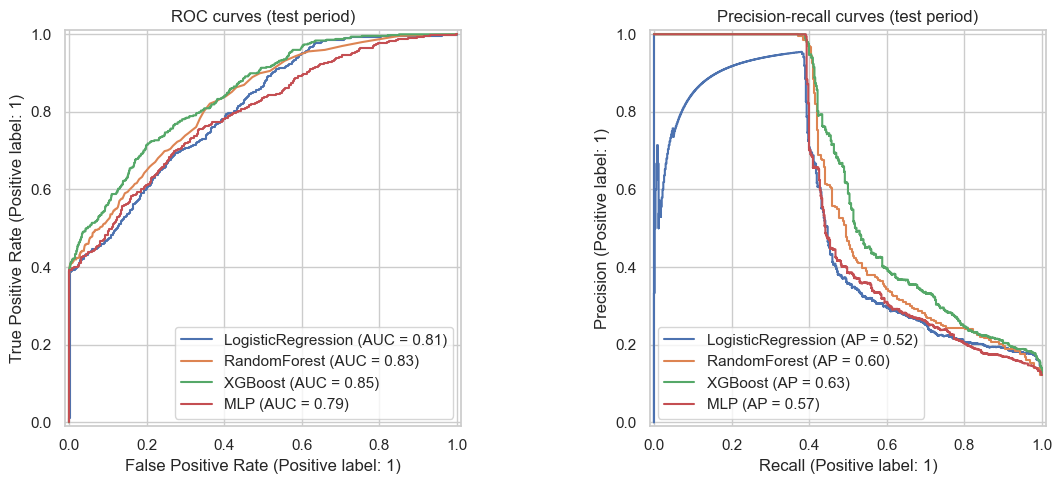

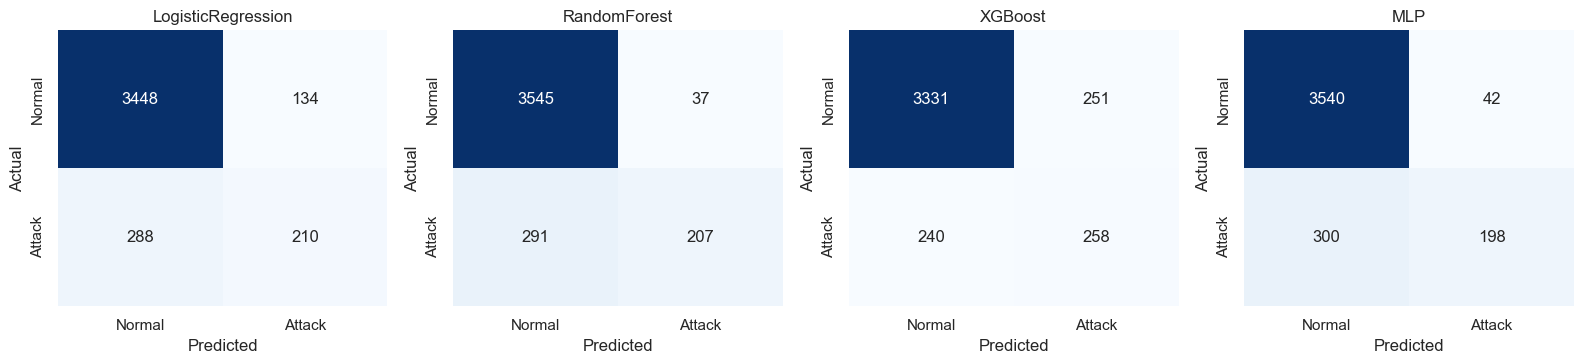

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name in MODELS:
    RocCurveDisplay.from_predictions(y_test, scores[name], name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, scores[name], name=name, ax=ax[1])
ax[0].set_title("ROC curves (test period)"); ax[1].set_title("Precision-recall curves (test period)")
save_fig("fig_roc_pr.png")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, name in zip(axes, MODELS):
    sns.heatmap(confusion_matrix(y_test, preds[name]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
save_fig("fig_confusion_matrices.png")

## Step 12: Isolation Forest (trained on normal training records only)

In [12]:
iso = make_pipeline(IsolationForest(n_estimators=300, random_state=SEED)).fit(X_train[y_train == 0])
thr = np.quantile(-iso.decision_function(X_train[y_train == 0]), 0.95)
iso_score = -iso.decision_function(X_test)
RESULTS["iforest"] = evaluate(y_test, (iso_score > thr).astype(int), iso_score)
pd.DataFrame([RESULTS["iforest"]], index=["IsolationForest"]).round(4)

,Accuracy,Precision,Recall,F1,FPR,MCC,ROC-AUC,PR-AUC,TP,FP,FN,TN
IsolationForest,0.8571,0.4162,0.4237,0.4199,0.0826,0.3384,0.6429,0.4179,211,296,287,3286


## Step 13: Three-class threat categorizer

                 precision    recall  f1-score   support

         Normal     0.9225    0.9975    0.9586      3582
       Spoofing     0.5000    0.0100    0.0196       300
Data Alteration     0.9701    0.9848    0.9774       198

       accuracy                         0.9243      4080
      macro avg     0.7976    0.6641    0.6519      4080
   weighted avg     0.8938    0.9243    0.8904      4080



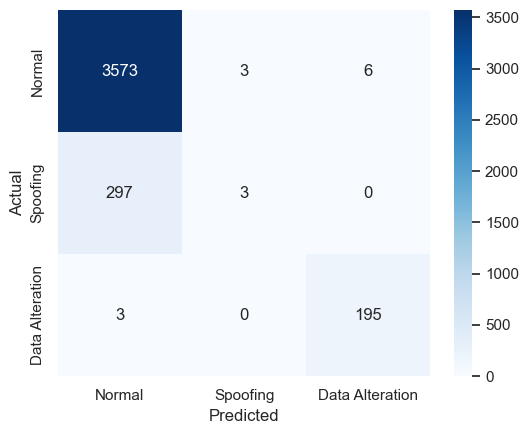

In [13]:
label_enc = LabelEncoder().fit(gov["Attack Category"])
xgb_multi = make_pipeline(new_xgb(eval_metric="mlogloss")).fit(X_train, label_enc.transform(ym_train))
pred_multi = label_enc.inverse_transform(xgb_multi.predict(X_test))
order = ["Normal", "Spoofing", "Data Alteration"]
RESULTS["multiclass"] = {"report": classification_report(ym_test, pred_multi, labels=order, output_dict=True, zero_division=0),
                         "cm": confusion_matrix(ym_test, pred_multi, labels=order).tolist(), "order": order}
print(classification_report(ym_test, pred_multi, labels=order, digits=4, zero_division=0))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(ym_test, pred_multi, labels=order), annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.xlabel("Predicted"); plt.ylabel("Actual"); save_fig("fig_multiclass_cm.png")

## Step 14: Ablation (do the vital signs still help under the time split?)
Each configuration is scored by time-blocked CV on the training period **and** on the later test period.
The last row adds `Flgs` back only as a reference for how much the excluded artifact would inflate results.

In [14]:
feature_sets = {
    "Network + vital signs (main model)": (NETWORK + VITALS, []),
    "Network only": (NETWORK, []),
    "Vital signs only": (VITALS, []),
    "Network + vital signs without temperature": (NETWORK + [v for v in VITALS if v != "Temp"], []),
    "Reference: network + vital signs + Flgs (excluded)": (NETWORK + VITALS, FLAGS),
}
abl, abl_pred = {}, {}
for label, (nc, cc) in feature_sets.items():
    cols = nc + cc
    s_cv = cross_validate(make_pipeline(new_xgb(scale_pos_weight=pos_weight, eval_metric="logloss"), nc, cc),
                          train_df[cols], y_train, cv=CV_FOLDS, scoring=["f1", "recall", "roc_auc"])
    p = make_pipeline(new_xgb(scale_pos_weight=pos_weight, eval_metric="logloss"), nc, cc).fit(train_df[cols], y_train)
    sc_t = p.predict_proba(test_df[cols])[:, 1]; pr_t = (sc_t >= 0.5).astype(int)
    abl_pred[label] = pr_t
    abl[label] = {"n": len(cols), "cv_f1": [float(s_cv["test_f1"].mean()), float(s_cv["test_f1"].std(ddof=1))],
                  "cv_recall": float(s_cv["test_recall"].mean()), "cv_auc": float(s_cv["test_roc_auc"].mean()),
                  "test_f1": float(f1_score(y_test, pr_t)), "test_recall": float(recall_score(y_test, pr_t)),
                  "test_auc": float(roc_auc_score(y_test, sc_t)), "test_prauc": float(average_precision_score(y_test, sc_t))}
main_pred = abl_pred["Network + vital signs (main model)"]
def mcnemar_vs_main(other):
    ca, cb = main_pred == y_test, abl_pred[other] == y_test
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return {"n01": n01, "n10": n10, "p_exact": float(stats.binomtest(n01, n01 + n10, 0.5).pvalue) if n01 + n10 else 1.0}
for label in abl:
    if label != "Network + vital signs (main model)":
        abl[label]["mcnemar_vs_main"] = mcnemar_vs_main(label)
RESULTS["ablation"] = abl
abl_table = pd.DataFrame(abl).T
abl_table.to_csv(os.path.join(OUTPUT_DIR, "table_ablation.csv"))
abl_table.round(4)

,n,cv_f1,cv_recall,cv_auc,test_f1,test_recall,test_auc,test_prauc,mcnemar_vs_main
Network + vital signs (main model),29,"[0.5877855609992355, 0.13073815121168467]",0.517794,0.829229,0.512413,0.518072,0.84762,0.628813,NaN
Network only,21,"[0.5130225586001045, 0.06423533959354652]",0.643728,0.862928,0.453669,0.614458,0.846849,0.616998,"{'n01': 437, 'n10': 191, 'p_exact': 3.89837586..."
Vital signs only,8,"[0.2519860752479936, 0.061670706961594345]",0.372967,0.581889,0.243881,0.560241,0.600691,0.265477,"{'n01': 1493, 'n10': 254, 'p_exact': 3.1738369..."
Network + vital signs without temperature,28,"[0.5875228579259756, 0.15044669200438715]",0.505561,0.811234,0.479857,0.538153,0.843275,0.608986,"{'n01': 229, 'n10': 139, 'p_exact': 3.13946086..."
Reference: network + vital signs + Flgs (excluded),30,"[0.6452940987356632, 0.12565403357491373]",0.574985,0.850516,0.609977,0.540161,0.865726,0.686168,"{'n01': 26, 'n10': 173, 'p_exact': 7.738521883..."


## Step 15: Explainability — gain importance and SHAP (XGBoost built-in TreeSHAP)

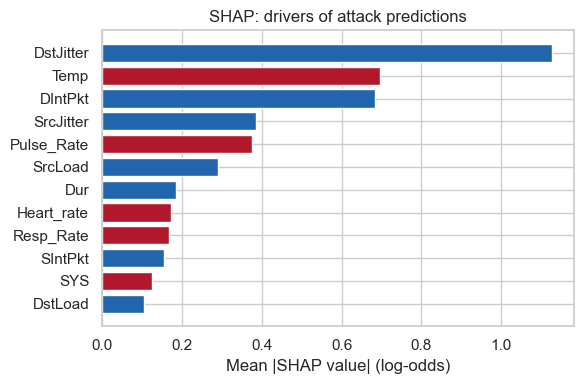

Share of total |SHAP|: {'Network telemetry': 0.6382443408687357, 'Vital signs (ePHI)': 0.3617556591312643}


DstJitter     1.1262
Temp          0.6949
DIntPkt       0.6827
SrcJitter     0.3859
Pulse_Rate    0.3744
SrcLoad       0.2888
Dur           0.1835
Heart_rate    0.1723
Resp_Rate     0.1680
SIntPkt       0.1548
SYS           0.1254
DstLoad       0.1035
dtype: float32

In [15]:
best = fitted["XGBoost"]
X_test_ready = best.named_steps["pre"].transform(X_test)
feature_names = [n.split("__", 1)[1] for n in best.named_steps["pre"].get_feature_names_out()]
gain = pd.Series(best.named_steps["clf"].feature_importances_, index=feature_names).sort_values(ascending=False)

booster = best.named_steps["clf"].get_booster()
dm = xgboost.DMatrix(X_test_ready, feature_names=feature_names)
contribs = booster.predict(dm, pred_contribs=True)            # TreeSHAP: one column per feature + bias
shap_vals, base_value = contribs[:, :-1], contribs[:, -1]
margin = booster.predict(dm, output_margin=True)
assert np.allclose(shap_vals.sum(axis=1) + base_value, margin, atol=1e-3), "SHAP additivity check failed"
mean_abs = pd.Series(np.abs(shap_vals).mean(axis=0), index=feature_names).sort_values(ascending=False)
grp = {"Network telemetry": float(mean_abs[NETWORK].sum()), "Vital signs (ePHI)": float(mean_abs[VITALS].sum())}
RESULTS["gain_importance"] = gain.round(4).to_dict()
RESULTS["shap_mean_abs"] = mean_abs.round(4).to_dict()
RESULTS["shap_group_share"] = {k: v / sum(grp.values()) for k, v in grp.items()}
np.save(os.path.join(OUTPUT_DIR, "shap_values_test.npy"), shap_vals)

top = mean_abs.head(12)[::-1]
plt.figure(figsize=(6, 4))
plt.barh(top.index, top.values, color=["#B2182B" if f in VITALS else "#2166AC" for f in top.index])
plt.xlabel("Mean |SHAP value| (log-odds)"); plt.title("SHAP: drivers of attack predictions")
save_fig("fig_shap_summary.png")
print("Share of total |SHAP|:", RESULTS["shap_group_share"])
mean_abs.head(12).round(4)

## Step 16: Early detection in the test period
The model trained on the earlier period scores the later period in time order, as it would in deployment.

{
 "bursts": 20,
 "detected_share": 0.85,
 "first_record_share": 0.5,
 "by_category": {
  "Spoofing": {
   "bursts": 12,
   "detected": 9,
   "first_record": 2,
   "median_delay": 1.0,
   "max_delay": 13.0,
   "coverage_mean": 0.21403852870483528
  },
  "Data Alteration": {
   "bursts": 8,
   "detected": 8,
   "first_record": 8,
   "median_delay": 0.0,
   "max_delay": 0.0,
   "coverage_mean": 0.9919354838709677
  }
 }
}
Batch: 2.9 us per record | single record: 5.25 ms


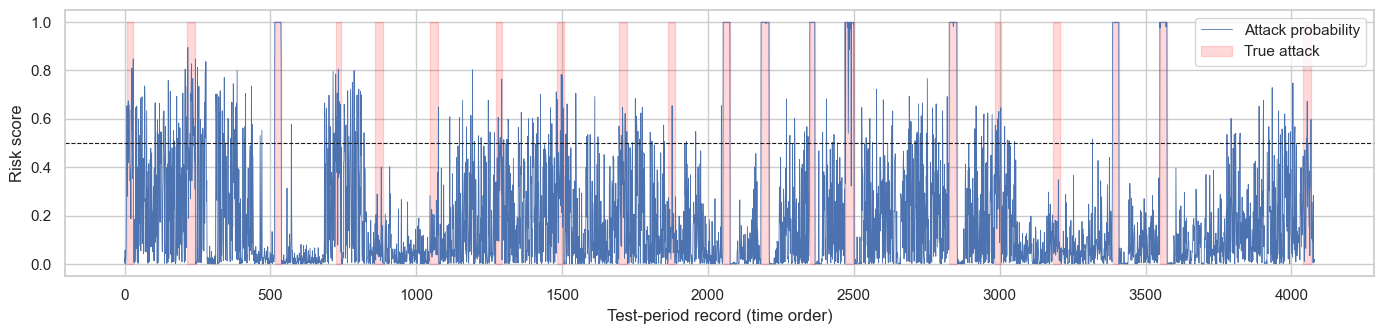

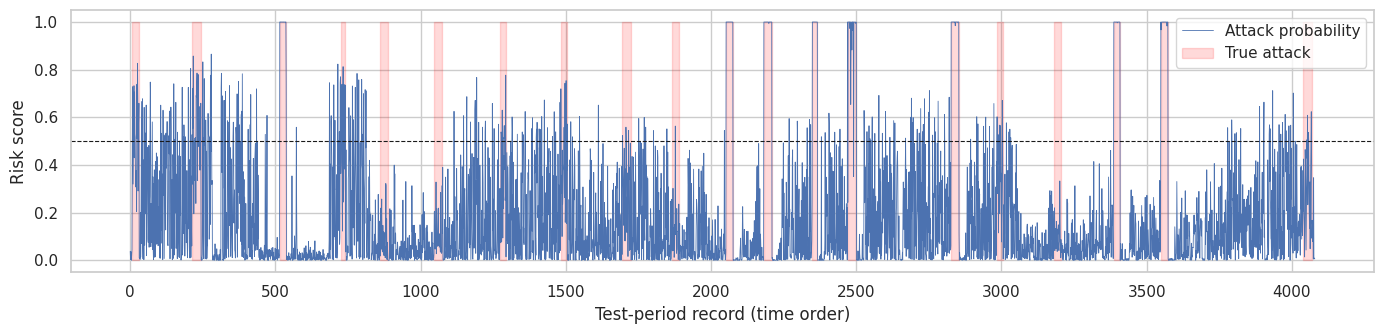

In [16]:
seq = test_df[["Packet_num", "Label", "Attack Category"]].copy()
seq["score"] = scores["XGBoost"]; seq["alert"] = preds["XGBoost"]
seq["burst"] = (seq["Label"] != seq["Label"].shift()).cumsum()
bl = []
for b_id, g in seq[seq["Label"] == 1].groupby("burst"):
    hits = np.flatnonzero(g["alert"].values)
    bl.append({"category": g["Attack Category"].mode()[0], "length": len(g), "detected": len(hits) > 0,
               "delay": int(hits[0]) if len(hits) else None, "coverage": float(g["alert"].mean())})
bl = pd.DataFrame(bl)
early = {"bursts": len(bl), "detected_share": float(bl["detected"].mean()),
         "first_record_share": float((bl["delay"] == 0).mean()),
         "by_category": {c: {"bursts": int((bl.category == c).sum()), "detected": int(bl[bl.category == c]["detected"].sum()),
                             "first_record": int((bl[bl.category == c]["delay"] == 0).sum()),
                             "median_delay": float(bl[bl.category == c]["delay"].median()),
                             "max_delay": float(bl[bl.category == c]["delay"].max()),
                             "coverage_mean": float(bl[bl.category == c]["coverage"].mean())}
                         for c in ["Spoofing", "Data Alteration"]}}
RESULTS["early"] = early
print(json.dumps(early, indent=1))

t0 = time.perf_counter(); best.predict_proba(X_test); batch_us = (time.perf_counter() - t0) / len(X_test) * 1e6
one = X_test.iloc[[0]]; t0 = time.perf_counter()
for _ in range(200): best.predict_proba(one)
single_ms = (time.perf_counter() - t0) / 200 * 1e3
RESULTS["timing"] = {"batch_us": batch_us, "single_ms": single_ms}
print(f"Batch: {batch_us:.1f} us per record | single record: {single_ms:.2f} ms")

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(np.arange(len(seq)), seq["score"], lw=0.6, label="Attack probability")
ax.fill_between(np.arange(len(seq)), 0, 1, where=seq["Label"] == 1, color="red", alpha=0.15, step="mid", label="True attack")
ax.axhline(0.5, ls="--", c="k", lw=0.8); ax.set_xlabel("Test-period record (time order)"); ax.set_ylabel("Risk score")
ax.legend(loc="upper right"); save_fig("fig_streaming_detection.png")

## Step 17: Mitigation layer (test period)

In [17]:
POLICY = [(0.90, "CRITICAL"), (0.70, "HIGH"), (0.50, "MEDIUM"), (0.30, "LOW"), (0.00, "NONE")]
def tier_of(score):
    return next(t for m, t in POLICY if score >= m)
inc = pd.DataFrame({"score": scores["XGBoost"], "pred_category": pred_multi, "true_category": ym_test})
inc["tier"] = inc["score"].map(tier_of)
inc["breach_flag"] = inc["tier"].isin(["HIGH", "CRITICAL"]) & (inc["pred_category"] == "Data Alteration")
tiers = pd.crosstab(inc["tier"], inc["true_category"]).reindex([t for _, t in POLICY]).fillna(0).astype(int)
RESULTS["tiers"] = tiers.to_dict()
RESULTS["breach"] = {"flags": int(inc["breach_flag"].sum()),
                     "true_alteration": int((inc["breach_flag"] & (inc["true_category"] == "Data Alteration")).sum())}
for _, r in inc[inc["tier"].isin(["HIGH", "CRITICAL"])].head(50).iterrows():
    audit("mitigation_action", tier=r["tier"], score=round(float(r["score"]), 4), predicted=r["pred_category"],
          breach_assessment=bool(r["breach_flag"]))
print(RESULTS["breach"]); tiers

{'flags': 199, 'true_alteration': 195}


true_category,Data Alteration,Normal,Spoofing
tier,,,
CRITICAL,192,0,0
HIGH,3,38,15
MEDIUM,1,213,47
LOW,2,411,82
NONE,0,2920,156


## Step 18: Save model, results, and integrity check

In [18]:
MODEL_PATH = os.path.join(OUTPUT_DIR, "xgb_telemedicine_ids.joblib")
joblib.dump(best, MODEL_PATH)
model_hash = hashlib.sha256(open(MODEL_PATH, "rb").read()).hexdigest()
audit("model_saved", path=MODEL_PATH, sha256=model_hash)
assert fingerprint(raw) == raw_hash, "Source data changed during processing!"
RESULTS["integrity_ok"] = True
RESULTS["audit_entries"] = sum(1 for _ in open(AUDIT_LOG)) + 1
audit("results_saved", entries=RESULTS["audit_entries"])
np.savez(os.path.join(OUTPUT_DIR, "scores_test.npz"), y_test=y_test, ym_test=ym_test.astype(str), pred_multi=pred_multi.astype(str),
         iso=iso_score, **{k: v for k, v in scores.items()})
json.dump(RESULTS, open(os.path.join(OUTPUT_DIR, "results_v3.json"), "w"), indent=1, default=float)
print("Integrity check passed. Audit entries:", RESULTS["audit_entries"])

Integrity check passed. Audit entries: 57
